A Machine Learning Approach To Classifying Crefit Score

The credit score of a person determines the creditworthiness of the person. It helps financial companies determine if you can repay the loan or credit you are applying for. Today banks and credit card companies use Machine Learning algorithms to classify all the customers in their database based on their credit history.

There are three credit scores that banks and credit card companies use to label their customers:

1) Good
2) Standard
3) Poor

A healthy credit score will ease the process of getting a loan or credit card for the person applying for it.

Hence, in this project, I will be building an ML model based on Random Forest to help classify credit score of an individual based on several different factors that contribute to the score. The final classification will be:

1) Good
2) Standard
3) Poor

For this project, I will be using a dataset from Kaggle submitted by Rohan Paris.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from imbearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

from sklearn.model_selection import train_test_split

sns.set_style('whitegrid')

ModuleNotFoundError: No module named 'imbearn'

In [3]:

%pip install imbalanced-learn


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from imbearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

from sklearn.model_selection import train_test_split

sns.set_style('whitegrid')

ModuleNotFoundError: No module named 'imbearn'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

from sklearn.model_selection import train_test_split

sns.set_style('whitegrid')

ModuleNotFoundError: No module named 'imbearn'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from imblearn.under_sampling import RandomUnderSampler

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


In [4]:
from sklearn.model_selection import train_test_split

sns.set_style('whitegrid')

In [5]:
data = pd.read_csv(r"C:\Users\DELL\Downloads\credit_score_data.csv")

In [6]:
data

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.465380,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.465380,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.465380,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.465380,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.465380,High_spent_Medium_value_payments,341.489231,Good
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,155625,37932,4,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.663572,378.0,No,35.104023,24.028477,High_spent_Large_value_payments,479.866228,Poor
99996,155626,37932,5,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,40.565631,379.0,No,35.104023,24.028477,High_spent_Medium_value_payments,496.651610,Poor
99997,155627,37932,6,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,41.255522,380.0,No,35.104023,24.028477,High_spent_Large_value_payments,516.809083,Poor
99998,155628,37932,7,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,33.638208,381.0,No,35.104023,24.028477,Low_spent_Large_value_payments,319.164979,Standard


Data Validation

In [7]:
#Remove Unnecessary Columns

In [8]:
data = data.drop(['ID','Customer_ID','Month','Name','SSN'],axis=1)
data

,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.465380,High_spent_Small_value_payments,312.494089,Good
1,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.465380,Low_spent_Large_value_payments,284.629162,Good
2,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.465380,Low_spent_Medium_value_payments,331.209863,Good
3,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.465380,Low_spent_Small_value_payments,223.451310,Good
4,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.465380,High_spent_Medium_value_payments,341.489231,Good
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,25.0,Mechanic,39628.99,3359.415833,4.0,6.0,7.0,2.0,"Auto Loan, and Student Loan",23.0,...,Good,502.38,34.663572,378.0,No,35.104023,24.028477,High_spent_Large_value_payments,479.866228,Poor
99996,25.0,Mechanic,39628.99,3359.415833,4.0,6.0,7.0,2.0,"Auto Loan, and Student Loan",18.0,...,Good,502.38,40.565631,379.0,No,35.104023,24.028477,High_spent_Medium_value_payments,496.651610,Poor
99997,25.0,Mechanic,39628.99,3359.415833,4.0,6.0,7.0,2.0,"Auto Loan, and Student Loan",27.0,...,Good,502.38,41.255522,380.0,No,35.104023,24.028477,High_spent_Large_value_payments,516.809083,Poor
99998,25.0,Mechanic,39628.99,3359.415833,4.0,6.0,7.0,2.0,"Auto Loan, and Student Loan",20.0,...,Good,502.38,33.638208,381.0,No,35.104023,24.028477,Low_spent_Large_value_payments,319.164979,Standard


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 23 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Age                       100000 non-null  float64
 1   Occupation                100000 non-null  object 
 2   Annual_Income             100000 non-null  float64
 3   Monthly_Inhand_Salary     100000 non-null  float64
 4   Num_Bank_Accounts         100000 non-null  float64
 5   Num_Credit_Card           100000 non-null  float64
 6   Interest_Rate             100000 non-null  float64
 7   Num_of_Loan               100000 non-null  float64
 8   Type_of_Loan              100000 non-null  object 
 9   Delay_from_due_date       100000 non-null  float64
 10  Num_of_Delayed_Payment    100000 non-null  float64
 11  Changed_Credit_Limit      100000 non-null  float64
 12  Num_Credit_Inquiries      100000 non-null  float64
 13  Credit_Mix                100000 non-null  ob

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 23 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Age                       100000 non-null  float64
 1   Occupation                100000 non-null  object 
 2   Annual_Income             100000 non-null  float64
 3   Monthly_Inhand_Salary     100000 non-null  float64
 4   Num_Bank_Accounts         100000 non-null  float64
 5   Num_Credit_Card           100000 non-null  float64
 6   Interest_Rate             100000 non-null  float64
 7   Num_of_Loan               100000 non-null  float64
 8   Type_of_Loan              100000 non-null  object 
 9   Delay_from_due_date       100000 non-null  float64
 10  Num_of_Delayed_Payment    100000 non-null  float64
 11  Changed_Credit_Limit      100000 non-null  float64
 12  Num_Credit_Inquiries      100000 non-null  float64
 13  Credit_Mix                100000 non-null  ob

Check for Missing Values

In [11]:
data.isnull().sum()

Age                         0
Occupation                  0
Annual_Income               0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Type_of_Loan                0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Outstanding_Debt            0
Credit_Utilization_Ratio    0
Credit_History_Age          0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Payment_Behaviour           0
Monthly_Balance             0
Credit_Score                0
dtype: int64

There are no missing values present in our dataset. Therefore, we don't have to worry about handling them.

Check for Duplicated Data

Next, we should check if there are duplicated rows in our dataset. Duplicates don't provide the correct picture of the dataset and may be biased. Moreover, they cause an ML model to overfit and learn the random noise rather than the general patterns in the dataset. Hence, we should remove any duplicated data.

In [12]:
data.duplicated().sum()

0

We can see there are no duplicate rows in our dataset, so we do not need to drop any data.

Check for Dataset Imbalance 

As our final step in data validation, we need to check our dataset is balanced. That is, if there are equal no. of observations in each of the classes labelled in our dataset. Class imbalance can cause bias and lead to inaccurate ML models.

In [13]:
data['Credit_Score'].value_counts(normalize=True)

Credit_Score
Standard    0.53174
Poor        0.28998
Good        0.17828
Name: proportion, dtype: float64

We can see there is a huge class imbalance in the dataset. More than 50% of the observations belong to the 'Standard' score, almost 30% to 'Poor' and the rest to 'Good'. This will indeed be a problem down the road, and we would need to balance the dataset before training an ML model on it.

Exploratory Data Analysis (EDA)

EDA is a crucial step in data analysis as it tells us about the underlying hidden patterns in the dataset that can aid further advanced analysis or model building.

Our dataset has many features that can train a Machine Learning model for credit score classification. Let’s explore all the features one by one.

Occupation vs. Credit Score

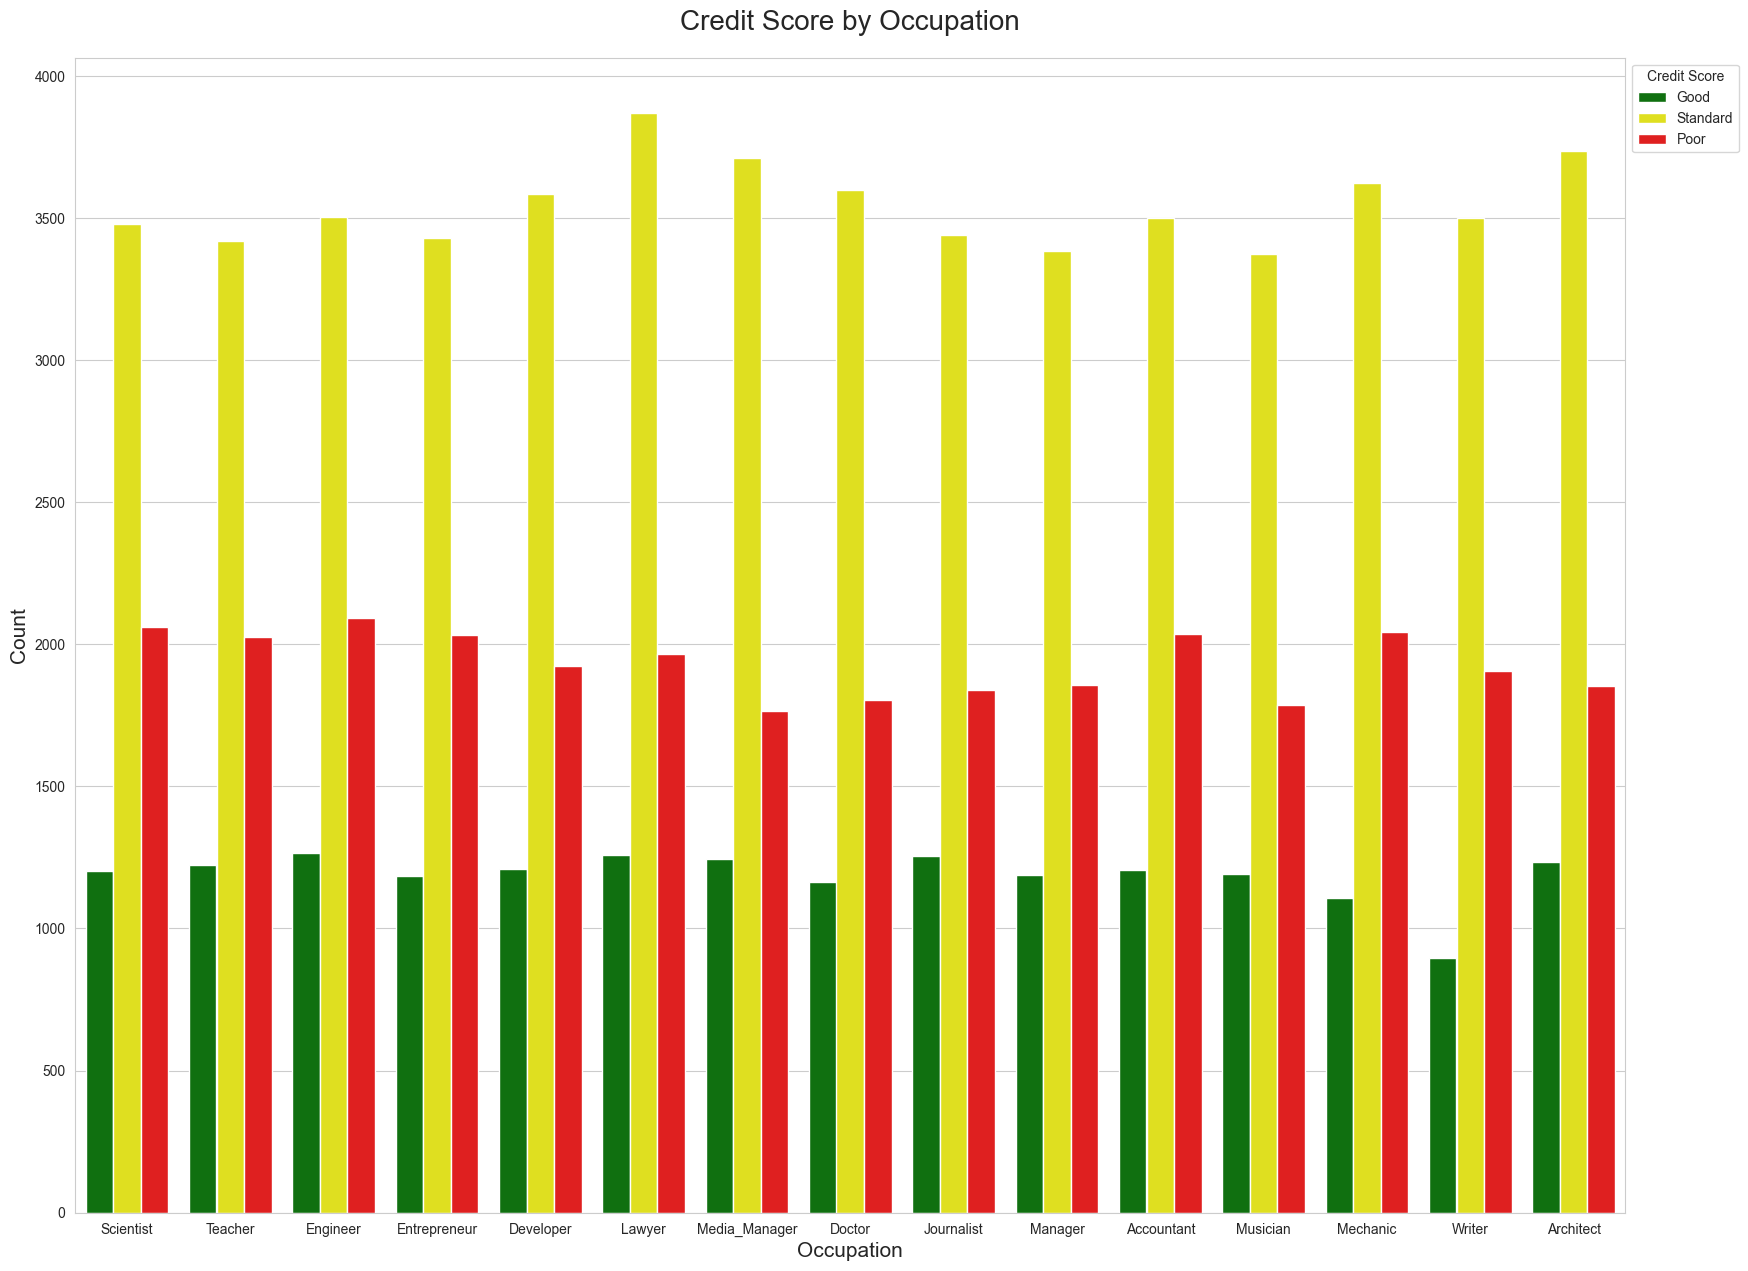

In [14]:
plt.figure(figsize=(20,15))
sns.countplot(data=data, x='Occupation' , hue='Credit_Score', palette=['green','yellow','red'])
plt.xlabel('Occupation', fontsize=15)
plt.ylabel('Count', fontsize=15)
plt.legend(title='Credit Score', bbox_to_anchor=(1,1))
plt.title('Credit Score by Occupation', fontsize=20, pad=20)
plt.show()

From the graph, there's no explicit trend between credit scores and occupation, as their distribution is quite similar to each other.

Annual Income vs. Credit Score

Now let’s explore whether the Annual Income of the person impacts your credit scores or not.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


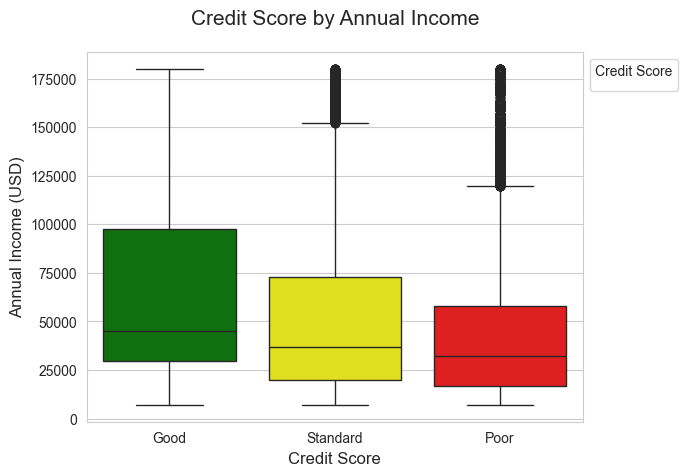

In [15]:
sns.boxplot(data=data, x='Credit_Score', y='Annual_Income', hue='Credit_Score', palette=['green','yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Annual Income (USD)', fontsize=12)
plt.legend(title='Credit Score', bbox_to_anchor=(1,1))
plt.title('Credit Score by Annual Income', fontsize=15, pad=20)
plt.show()

According to the graph above, the more an individual earns yearly, the greater his/her chance to have a good credit score.

Monthly In-hand Salary vs Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


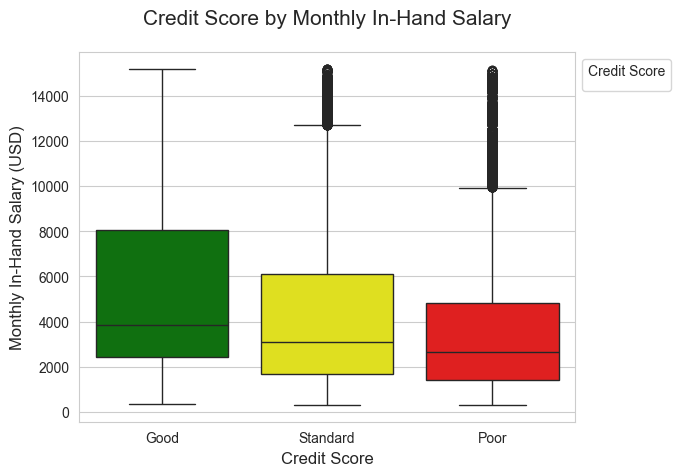

In [16]:
sns.boxplot(data=data, x='Credit_Score', y='Monthly_Inhand_Salary', hue='Credit_Score', palette=['green','yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Monthly In-Hand Salary (USD)', fontsize=12)
plt.legend(title='Credit Score', bbox_to_anchor=(1,1))
plt.title('Credit Score by Monthly In-Hand Salary', fontsize=15, pad=20)
plt.show()


Similar to annual income, the more monthly in-hand salary you earn, the better your credit score will become.

Number of Bank Account vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


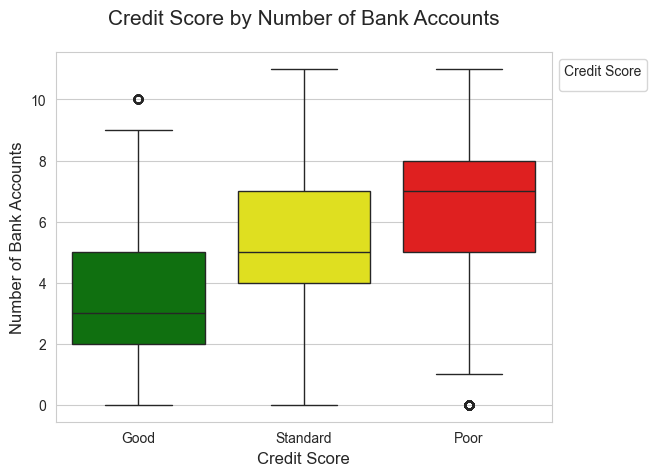

In [17]:
sns.boxplot(data=data, x='Credit_Score', y='Num_Bank_Accounts', hue='Credit_Score', palette=['green','yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Number of Bank Accounts', fontsize=12)
plt.legend(title='Credit Score', bbox_to_anchor=(1,1))
plt.title('Credit Score by Number of Bank Accounts', fontsize=15, pad=20)
plt.show()


Just like the number of bank accounts, having more credit cards will not positively impact an individual's credit scores. Having between 3-5 credit cards is okay.

Interest Rate vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


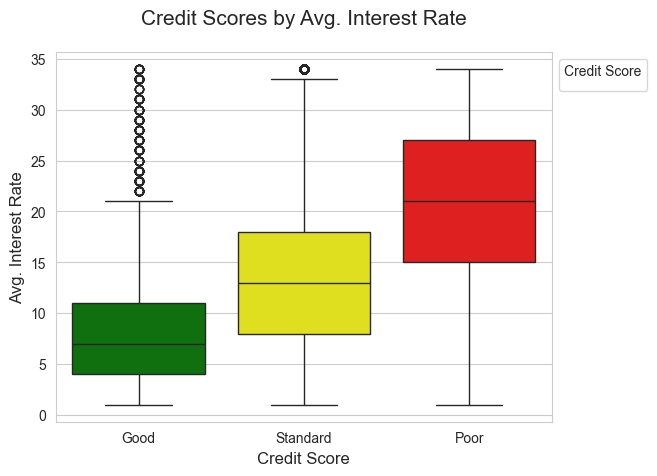

In [18]:
sns.boxplot(data=data, x='Credit_Score', y='Interest_Rate', hue='Credit_Score', palette=['green', 'yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Avg. Interest Rate', fontsize=12)
plt.legend(title='Credit Score',bbox_to_anchor=(1,1))
plt.title('Credit Scores by Avg. Interest Rate', fontsize=15, pad=20)
plt.show()

The graph tells us that having to pay a low interest rate is good for the credit score, with the ideal rate being 4-11%. However, anything more than 15% is bad.

Loans vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


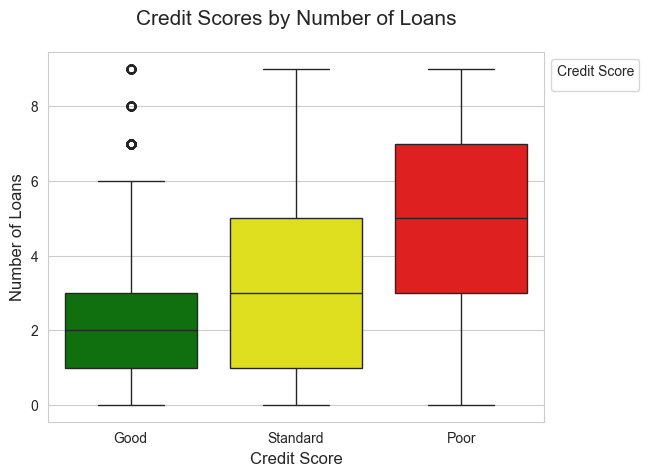

In [21]:
sns.boxplot(data=data, x='Credit_Score', y='Num_of_Loan', hue='Credit_Score', palette=['green', 'yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Number of Loans', fontsize=12)
plt.legend(title='Credit Score', bbox_to_anchor=(1,1))
plt.title('Credit Scores by Number of Loans', fontsize=15, pad=20)
plt.show()

Based on the data, to have a good credit score, you should not take more than 1 – 3 loans at a time. Having more than three loans at a time will negatively impact your credit scores, as you owe more money to financial institutions.

Delayed Payments vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


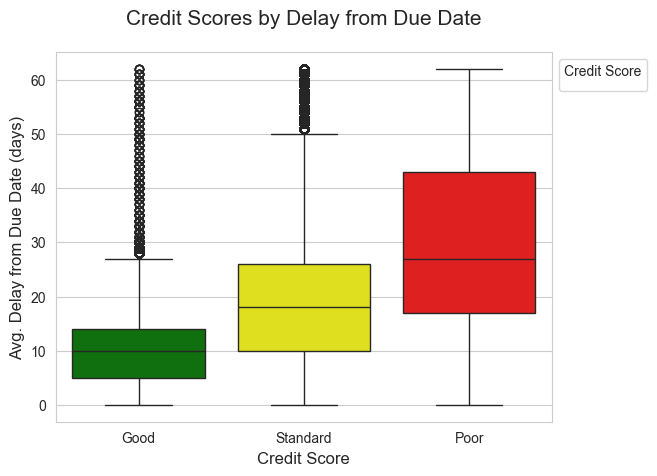

In [23]:
sns.boxplot(data=data, x='Credit_Score', y='Delay_from_due_date', hue='Credit_Score', palette=['green', 'yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Avg. Delay from Due Date (days)', fontsize=12)
plt.legend(title='Credit Score',bbox_to_anchor=(1,1))
plt.title('Credit Scores by Delay from Due Date', fontsize=15, pad=20)
plt.show()


We can see that one can delay their credit card payment 5 – 14 days from the due date and still have a good credit score. However, going beyond 17 days from the due date will impact your credit scores negatively.

Delay Frequency vs.Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


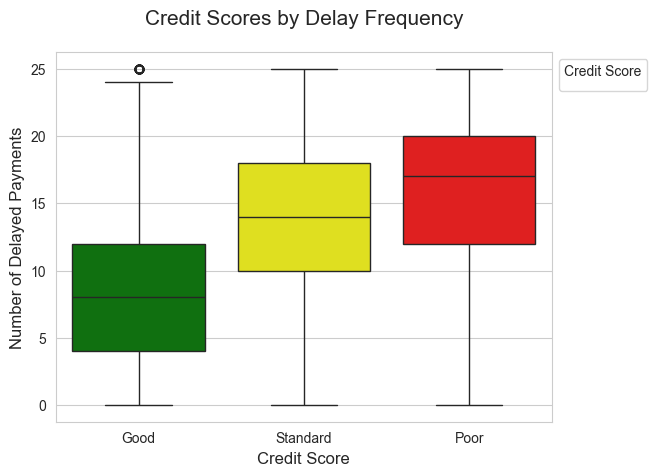

In [24]:
sns.boxplot(data=data, x='Credit_Score', y='Num_of_Delayed_Payment', hue='Credit_Score', palette=['green', 'yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Number of Delayed Payments', fontsize=12)
plt.legend(title='Credit Score',bbox_to_anchor=(1,1))
plt.title('Credit Scores by Delay Frequency', fontsize=15, pad=20)
plt.show()

It can be seen that the more payments one delays from the due date, the higher the chance of ending up with a poor credit score. Delaying more than 10-12 payments really deteriorates the score.

Outstanding Debt vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


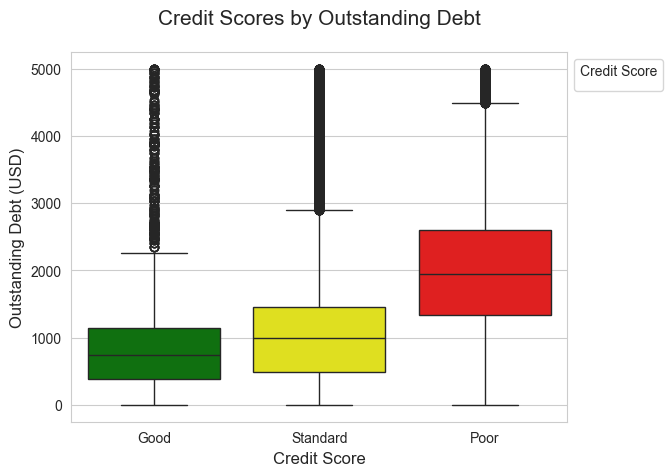

In [25]:
sns.boxplot(data=data, x='Credit_Score', y='Outstanding_Debt', hue='Credit_Score', palette=['green', 'yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Outstanding Debt (USD)', fontsize=12)
plt.legend(title='Credit Score',bbox_to_anchor=(1,1))
plt.title('Credit Scores by Outstanding Debt', fontsize=15, pad=20)
plt.show()

An outstanding debt of USD 380–1150 will not affect your credit scores too badly. But always having a debt of more than $1338 will affect your credit scores negatively.

Credit Utilisation vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


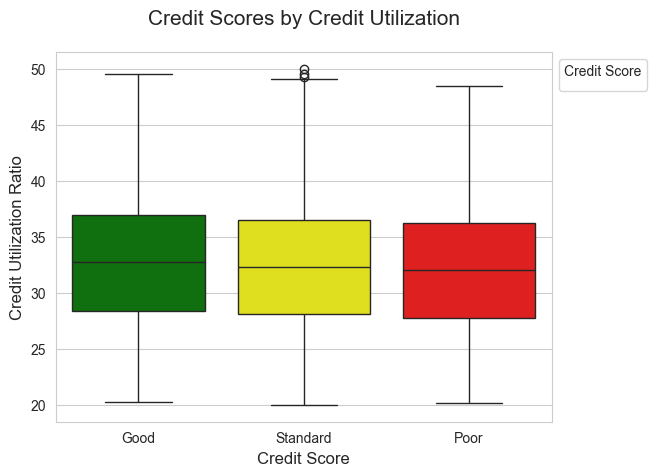

In [26]:
sns.boxplot(data=data, x='Credit_Score', y='Credit_Utilization_Ratio', hue='Credit_Score', palette=['green','yellow','red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Credit Utilization Ratio', fontsize=12)
plt.legend(title='Credit Score', bbox_to_anchor=(1,1))
plt.title('Credit Scores by Credit Utilization', fontsize=15, pad=20)
plt.show()

Credit History Age vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


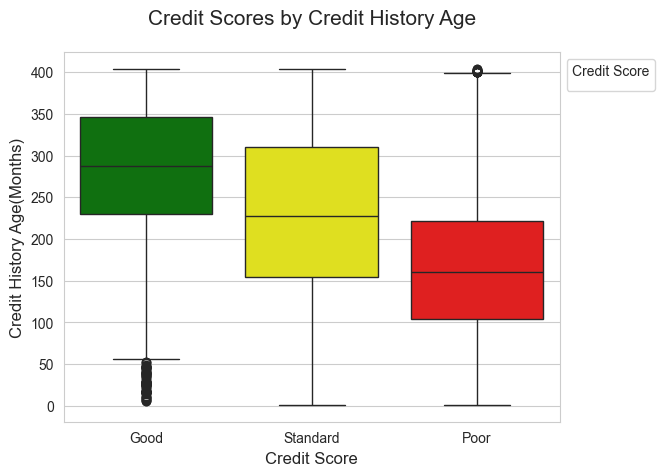

In [27]:
sns.boxplot(data=data, x='Credit_Score', y='Credit_History_Age', hue='Credit_Score', palette=['green', 'yellow','red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Credit History Age(Months)', fontsize=12)
plt.legend(title='Credit Score', bbox_to_anchor=(1,1))
plt.title('Credit Scores by Credit History Age', fontsize=15, pad=20)
plt.show()


Credit utilisation is calculated as total debt/total available credit. According to the above figure, your credit utilisation ratio barely affects your credit scores.

Credit History Age vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


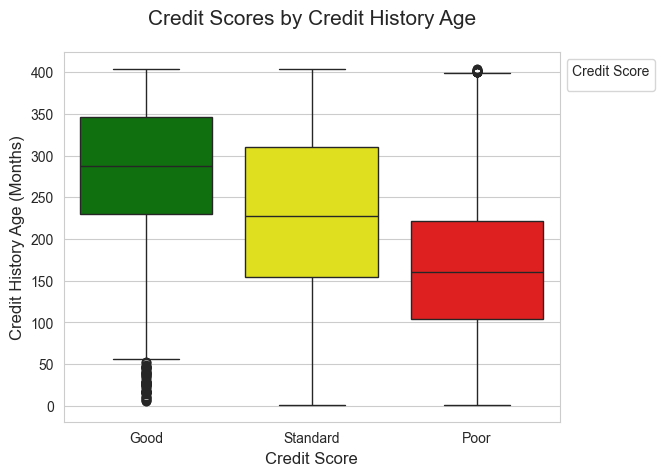

In [28]:
sns.boxplot(data=data, x='Credit_Score', y='Credit_History_Age', hue='Credit_Score', palette=['green','yellow','red'])
plt.xlabel('Credit Score', fontsize= 12)
plt.ylabel('Credit History Age (Months)', fontsize=12)
plt.legend(title='Credit Score', bbox_to_anchor=(1,1))
plt.title('Credit Scores by Credit History Age', fontsize=15, pad=20)
plt.show()

 having a long credit history results in better credit scores. It shows your ability to repay debts for a long time.

EMI vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


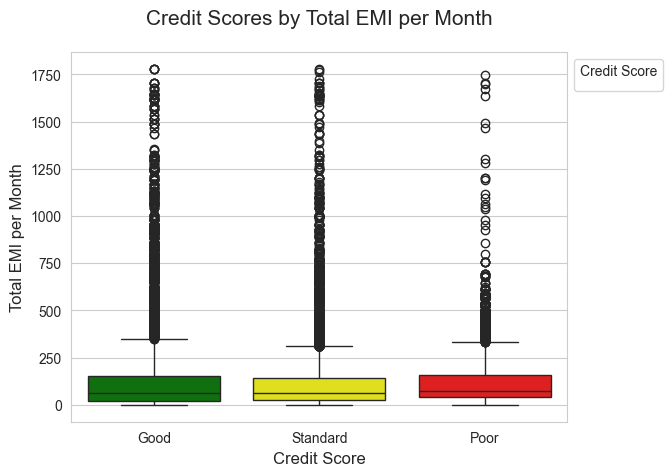

In [29]:
sns.boxplot(data=data, x='Credit_Score', y='Total_EMI_per_month', hue='Credit_Score', palette=['green', 'yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Total EMI per Month', fontsize=12)
plt.legend(title='Credit Score',bbox_to_anchor=(1,1))
plt.title('Credit Scores by Total EMI per Month', fontsize=15, pad=20)
plt.show()

The number of EMIs you are paying in a month don’t affect the credit scores by that much.

Monthly investment vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


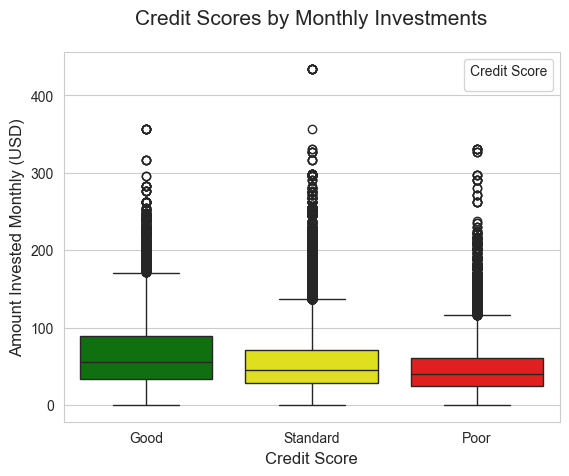

In [30]:
sns.boxplot(data=data, x='Credit_Score', y = 'Amount_invested_monthly', hue='Credit_Score', palette=['green','yellow','red'])
plt.xlabel('Credit Score', fontsize= 12)
plt.ylabel('Amount Invested Monthly (USD)', fontsize=12)
plt.legend(title='Credit Score', bbox_to_anchor=(1,1))
plt.title('Credit Scores by Monthly Investments', fontsize=15, pad=20)
plt.show()


The amount of money you invest monthly doesn’t affect your credit scores a lot. Still to have a good score, one could invest a bit more every month.

End of Month Balance vs. Credit Score

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


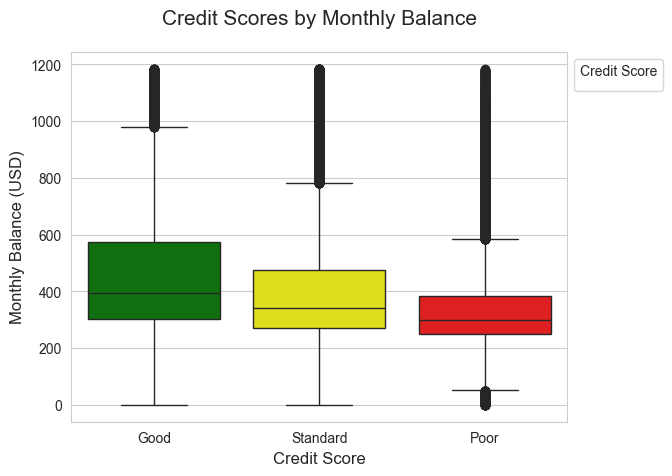

In [31]:
sns.boxplot(data=data, x='Credit_Score', y='Monthly_Balance', hue='Credit_Score', palette=['green', 'yellow', 'red'])
plt.xlabel('Credit Score', fontsize=12)
plt.ylabel('Monthly Balance (USD)', fontsize=12)
plt.legend(title='Credit Score',bbox_to_anchor=(1,1))
plt.title('Credit Scores by Monthly Balance', fontsize=15, pad=20)
plt.show()

According to our data, having a high monthly balance in your account at the end of the month is good for your credit scores. A monthly balance of less than USD 250 is bad.

With that we are done with EDA, and can proceed towards our main goal: build an ML model to predict credit score of an individual based on certain factors.

Handling Categorical Data

In our dataset, we have one more important feature (Credit Mix) that is valuable for determining one's credit score. The credit mix feature tells about the types of credits and loans an individual has taken.

As the Credit_Mix column is categorical, I will transform it into a numerical feature so that we can use it to in the training of an ML model for the task of credit score classification.

In [32]:
data['Credit_Mix'] = data['Credit_Mix'].map({'Bad':0, 'Standard': 1, 'Good':2})
data['Credit_Mix']

0        2
1        2
2        2
3        2
4        2
        ..
99995    2
99996    2
99997    2
99998    2
99999    2
Name: Credit_Mix, Length: 100000, dtype: int64

In [33]:
data['Credit_Mix'].unique()

array([2, 1, 0], dtype=int64)

Model Building 

Split into Features and Target
Now that our data is validated we can proceed to build the ML model. First, I will be splitting the whole dataset into two: features and target. The model will be built on the features to accurately predict the target variable.

For the split, I will only be selecting a few features that I found to be important factors for determining credit score.

In [34]:
feature_cols = ["Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment", "Credit_Mix", "Outstanding_Debt", "Credit_History_Age", "Monthly_Balance"]

In [36]:
x = data[feature_cols]
y = data['Credit_Score']

In [37]:
x.head()

,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Credit_Mix,Outstanding_Debt,Credit_History_Age,Monthly_Balance
0,19114.12,1824.843333,3.0,4.0,3.0,4.0,3.0,7.0,2,809.98,265.0,312.494089
1,19114.12,1824.843333,3.0,4.0,3.0,4.0,3.0,4.0,2,809.98,266.0,284.629162
2,19114.12,1824.843333,3.0,4.0,3.0,4.0,3.0,7.0,2,809.98,267.0,331.209863
3,19114.12,1824.843333,3.0,4.0,3.0,4.0,5.0,4.0,2,809.98,268.0,223.451310
4,19114.12,1824.843333,3.0,4.0,3.0,4.0,6.0,4.0,2,809.98,269.0,341.489231


In [38]:
y.head()

0    Good
1    Good
2    Good
3    Good
4    Good
Name: Credit_Score, dtype: object

Class Balancing

At the beginning of the project, during data validation, we saw that there was class imbalance in the dataset that can lead to bias and inaccurate model. Hence, now we need to handle it.

For this, I will be under-sampling the dataset so that there are the same number of observations in each class as that in the minority class.

In [39]:
print(f'Class Proportion before Balancing:\n{y.value_counts()}')

Class Proportion before Balancing:
Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64


In [40]:
rus = RandomUnderSampler(random_state=42)
x_rus, y_rus = rus.fit_resample(x,y)

In [41]:
print(f'Class Proportion after Balancing:\n{y_rus.value_counts()}')

Class Proportion after Balancing:
Credit_Score
Good        17828
Poor        17828
Standard    17828
Name: count, dtype: int64


In [42]:
print('Total Observations before Balancing :', y.count())
print('Total Observations before Balancing:', y_rus.count())

Total Observations before Balancing : 100000
Total Observations before Balancing: 53484


We have successfully balanced our dataset. As we can see, there are equal number of observations (17828) in all 3 classes present in the dataset. However, one slight drawback that we now have is that our total dataset size has been reduced from 100000 to 53484 after balancing. But, since the new dataset size is still quite large, I don't think it will affect our model negatively.

Split into Train and Test

Now, we may split the dataset into train and test. The model I will build will be trained on the training dataset only and later tested on the test dataset to see if it has generalised properly to unseen data. However, we still need to make sure there are equal number of observations for each of the classes in both the sets, so we will use stratified split.

In [43]:
# split into 80:20 ratio
# use random state for replicability
# use stratify to maintain class balance

x_train, x_test, y_train, y_test = train_test_split(x_rus, y_rus, test_size=0.2, random_state=42, stratify=y_rus)

In [44]:
print(x_train.shape, x_test.shape)

(42787, 12) (10697, 12)


In [45]:
print(y_train.shape, y_test.shape)

(42787,) (10697,)


We can see that the split was successful. The test dataset contains 20% of the original data, while the train dataset contains the rest 80%. Let's see if the class balance has been maintained too.

In [46]:
y_train.value_counts()

Credit_Score
Good        14263
Standard    14262
Poor        14262
Name: count, dtype: int64

In [48]:
y_test.value_counts()

Credit_Score
Standard    3566
Poor        3566
Good        3565
Name: count, dtype: int64

We can see that the class balance has been quite maintained. Now we can proceed for building the model.

Random Forest Classifier


A random forest is a meta estimator that fits a number of decision tree classifiers on various sub-samples of the dataset and uses averaging to improve the predictive accuracy and control over-fitting.

Since all our features are numeric, we can use them as the nodes of the decision trees.

Hence, let's build a Random Forest classifier and train on the training dataset.

In [49]:
model = RandomForestClassifier()
model.fit(x_train, y_train)

RandomForestClassifier()

In [50]:
y_preds = model.predict(x_test)

In [51]:
y_preds

array(['Standard', 'Standard', 'Good', ..., 'Standard', 'Standard',
       'Good'], dtype=object)

In [52]:
accuracy_score(y_test, y_preds)

0.8207908759465271

The model built has a good enough accuracy of 82% in classifying an individual's credit score. It may be improved further by fine tuning the hyper-parameters or building a hybrid model using multiple ML models in a later project.

In [53]:
y_copy = pd.DataFrame(y_test.copy())

In [55]:
y_copy['Preds'] = y_preds
y_copy

,Credit_Score,Preds
16825,Standard,Standard
48608,Poor,Standard
9034,Good,Good
3019,Standard,Standard
14888,Good,Good
...,...,...
95762,Standard,Poor
53059,Good,Good
19001,Standard,Standard
70104,Standard,Standard


From the above table, it can be observed that the model is pretty good in identifying a good credit score. However, it runs into confusion while differentiating between poor and standard.

User Inputs


Now, let’s make predictions from our model by giving inputs to our model according to the features we used to train the model.

In [56]:
print('Credit Score Classification:')
ann_inc = float(input("Annual Income: "))
mon_sal = float(input("Monthly Inhand Salary: "))
num_acc = float(input("Number of Bank Accounts: "))
num_cc = float(input("Number of Credit cards: "))
int_rate = float(input("Interest rate: "))
num_loan = float(input("Number of Loans: "))
delay = float(input("Average number of days delayed by the person: "))
num_delay = float(input("Number of delayed payments: "))
cred_mix = input("Credit Mix (Bad: 0, Standard: 1, Good: 3) : ")
out_debt = float(input("Outstanding Debt: "))
cred_his_age = float(input("Credit History Age: "))
mon_bal = float(input("Monthly Balance: "))

print('Predicted Credit Score:', model.predict(np.array([[ann_inc, mon_sal, num_acc, num_cc, int_rate, num_loan, delay, num_delay, cred_mix, out_debt, cred_his_age, mon_bal]]))[0])

Credit Score Classification:


Annual Income:  6000000
Monthly Inhand Salary:  500000
Number of Bank Accounts:  5
Number of Credit cards:  3
Interest rate:  4
Number of Loans:  4
Average number of days delayed by the person:  1
Number of delayed payments:  3
Credit Mix (Bad: 0, Standard: 1, Good: 3) :  3
Outstanding Debt:  8
Credit History Age:  2
Monthly Balance:  900000


Predicted Credit Score: Standard


C:\Users\DELL\python\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
